# Android Games

### Business Problem:  Which game characteristics, such as genre, price, rating, and monetization model, are associated with higher downloads?
### Help game companies understand what factors may contribute to game popularity

In [1]:
import pandas as pd

import numpy as np

import seaborn as sns

import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv(r"C:\Users\MEGHANA\OneDrive\Desktop\android_games_eda_ready.csv")
df

,game_id,game_name,developer_name,package_name,genre,sub_genre,monetization_model,contains_ads,has_in_app_purchases,multiplayer_support,...,has_seasonal_event,cross_platform_available,cloud_save_support,is_hit_game,post_30d_revenue_usd,post_30d_rating_count,featured_duration_days,store_platform,country_code_primary,row_checksum_id
0,622,Game_622_Arena,Studio_205,com.studio1664.game622,Casual,Party Game,Freemium,Yes,Yes,NaN,...,False,True,True,0,9963.75,6328,NaN,Android,IN,CHK_100621
1,4386,Game_4386_Rush,Studio_923,com.studio1615.game4386,RPG,Idle RPG,Free,Yes,No,Online,...,False,True,False,0,17880.43,9346,NaN,Android,IN,CHK_104385
2,6795,Game_6795_Tycoon,Studio_921,com.studio44.game6795,RPG,Idle RPG,Free,Yes,No,NaN,...,True,False,False,0,6060.03,4096,7.0,Android,BR,CHK_106794
3,4563,Game_4563_Quest,Studio_1873,com.studio1353.game4563,Casual,Idle Clicker,Paid,No,Yes,NaN,...,False,False,False,0,816621.72,12402,NaN,Android,US,CHK_104562
4,9265,Game_9265_Legends,Studio_1608,com.studio1308.game9265,RPG,MMORPG,Free,Yes,No,NaN,...,True,False,True,0,159839.20,7517,NaN,Android,IN,CHK_109264
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10145,5735,Game_5735_Legends,Studio_1081,com.studio774.game5735,Action,Endless Runner,Freemium,Yes,No,NaN,...,False,False,True,0,841316.57,156319,12.0,Android,IN,CHK_105734
10146,5192,Game_5192_Arena,Studio_1591,com.studio2181.game5192,RPG,Turn-Based,Free,Yes,Yes,NaN,...,False,True,False,0,172807.46,49521,NaN,Android,IN,CHK_105191
10147,5391,Game_5391_Tycoon,Studio_1105,com.studio1086.game5391,Sports,Cricket,Free,Yes,Yes,Online,...,False,True,True,0,43861.19,3539,NaN,Android,IN,CHK_105390
10148,861,Game_861_Legends,Studio_1864,com.studio1402.game861,Casual,Hypercasual,Free,Yes,No,NaN,...,False,False,False,0,6529.90,3189,NaN,Android,IN,CHK_100860


In [20]:
df.shape

(10150, 57)

In [21]:
df.columns

Index(['game_id', 'game_name', 'developer_name', 'package_name', 'genre',
       'sub_genre', 'monetization_model', 'contains_ads',
       'has_in_app_purchases', 'multiplayer_support', 'age_rating',
       'art_style', 'engine_used', 'region_focus', 'publisher_tier',
       'event_theme', 'release_date', 'soft_launch_date', 'last_update_date',
       'was_featured_on_store', 'featured_start_date', 'featured_end_date',
       'price_usd', 'downloads', 'retention_day1_pct', 'retention_day7_pct',
       'retention_day30_pct', 'active_users_30d', 'avg_session_minutes',
       'avg_daily_sessions', 'crash_rate_pct', 'apk_size_mb',
       'update_frequency_days', 'rating_avg', 'rating_count', 'review_count',
       'marketing_spend_usd', 'cpi_usd', 'conversion_to_payer_pct',
       'ad_impressions_per_user', 'ad_revenue_share_pct',
       'iap_revenue_share_pct', 'arpu_usd', 'arppu_usd', 'wishlist_prelaunch',
       'total_revenue_usd', 'is_weekend_release', 'has_seasonal_event',
       'cr

In [22]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10150 entries, 0 to 10149
Data columns (total 57 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   game_id                   10150 non-null  int64  
 1   game_name                 10150 non-null  str    
 2   developer_name            10150 non-null  str    
 3   package_name              10150 non-null  str    
 4   genre                     10150 non-null  str    
 5   sub_genre                 10150 non-null  str    
 6   monetization_model        10150 non-null  str    
 7   contains_ads              10150 non-null  str    
 8   has_in_app_purchases      10150 non-null  str    
 9   multiplayer_support       6084 non-null   str    
 10  age_rating                10150 non-null  str    
 11  art_style                 10150 non-null  str    
 12  engine_used               10150 non-null  str    
 13  region_focus              10150 non-null  str    
 14  publisher_tier   

In [23]:
df.isnull().sum()

game_id                        0
game_name                      0
developer_name                 0
package_name                   0
genre                          0
sub_genre                      0
monetization_model             0
contains_ads                   0
has_in_app_purchases           0
multiplayer_support         4066
age_rating                     0
art_style                      0
engine_used                    0
region_focus                   0
publisher_tier                 0
event_theme                 7682
release_date                   0
soft_launch_date            1012
last_update_date               0
was_featured_on_store          0
featured_start_date         6805
featured_end_date           6808
price_usd                      0
downloads                      0
retention_day1_pct             0
retention_day7_pct             0
retention_day30_pct            0
active_users_30d               0
avg_session_minutes            0
avg_daily_sessions             0
crash_rate

In [24]:
df.isnull().sum().sum()

np.int64(35381)

In [25]:
df.duplicated().sum()

np.int64(150)

In [26]:
df.nunique()

game_id                     10000
game_name                   10000
developer_name               2222
package_name                10000
genre                           8
sub_genre                      31
monetization_model              4
contains_ads                    2
has_in_app_purchases            2
multiplayer_support             3
age_rating                      3
art_style                       5
engine_used                     4
region_focus                    6
publisher_tier                  4
event_theme                     5
release_date                 2819
soft_launch_date             2872
last_update_date             3140
was_featured_on_store           2
featured_start_date          2029
featured_end_date            1988
price_usd                     688
downloads                    9855
retention_day1_pct           3463
retention_day7_pct           2581
retention_day30_pct          1673
active_users_30d             8250
avg_session_minutes          2972
avg_daily_sess

In [27]:
df = df.drop_duplicates()

In [28]:
df.duplicated().sum()

np.int64(0)

In [3]:
num_cols = df.select_dtypes(include='number').columns

num_cols

Index(['game_id', 'price_usd', 'downloads', 'retention_day1_pct',
       'retention_day7_pct', 'retention_day30_pct', 'active_users_30d',
       'avg_session_minutes', 'avg_daily_sessions', 'crash_rate_pct',
       'apk_size_mb', 'update_frequency_days', 'rating_avg', 'rating_count',
       'review_count', 'marketing_spend_usd', 'cpi_usd',
       'conversion_to_payer_pct', 'ad_impressions_per_user',
       'ad_revenue_share_pct', 'iap_revenue_share_pct', 'arpu_usd',
       'arppu_usd', 'wishlist_prelaunch', 'total_revenue_usd', 'is_hit_game',
       'post_30d_revenue_usd', 'post_30d_rating_count',
       'featured_duration_days'],
      dtype='str')

In [4]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 10150 entries, 0 to 10149
Data columns (total 57 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   game_id                   10150 non-null  int64  
 1   game_name                 10150 non-null  str    
 2   developer_name            10150 non-null  str    
 3   package_name              10150 non-null  str    
 4   genre                     10150 non-null  str    
 5   sub_genre                 10150 non-null  str    
 6   monetization_model        10150 non-null  str    
 7   contains_ads              10150 non-null  str    
 8   has_in_app_purchases      10150 non-null  str    
 9   multiplayer_support       6084 non-null   str    
 10  age_rating                10150 non-null  str    
 11  art_style                 10150 non-null  str    
 12  engine_used               10150 non-null  str    
 13  region_focus              10150 non-null  str    
 14  publisher_tier   

# Outliers

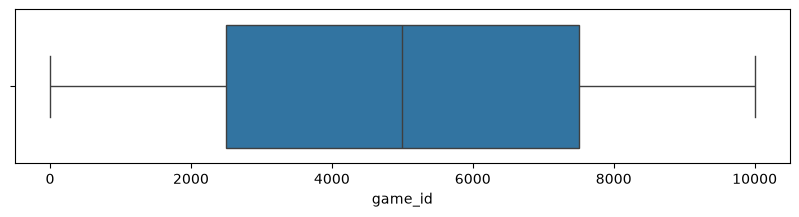

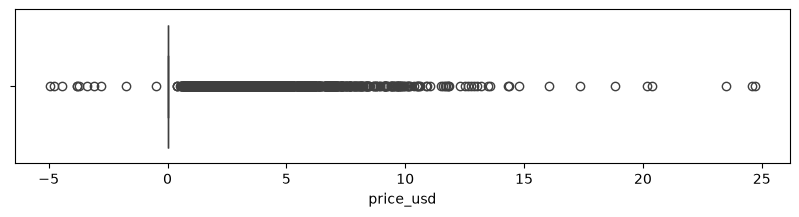

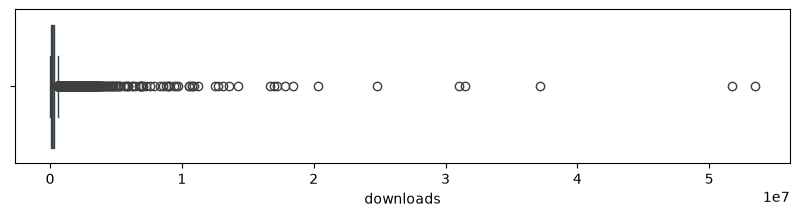

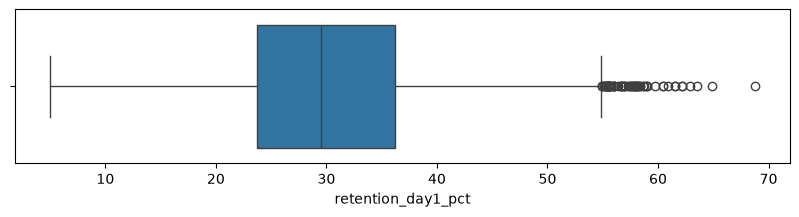

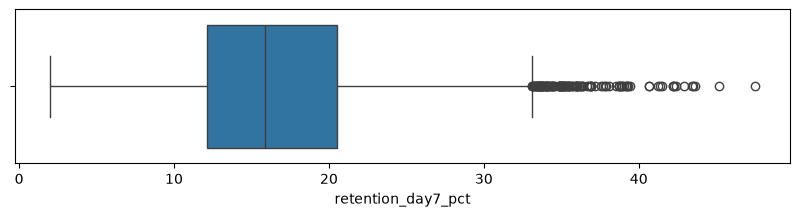

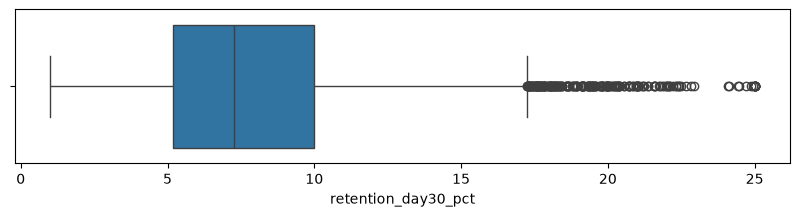

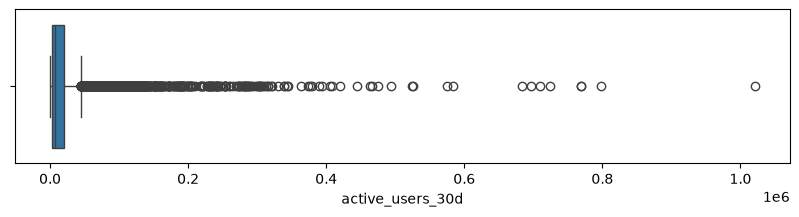

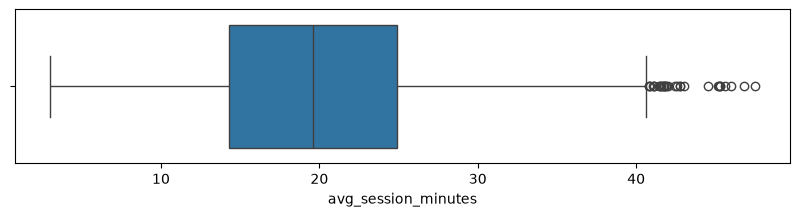

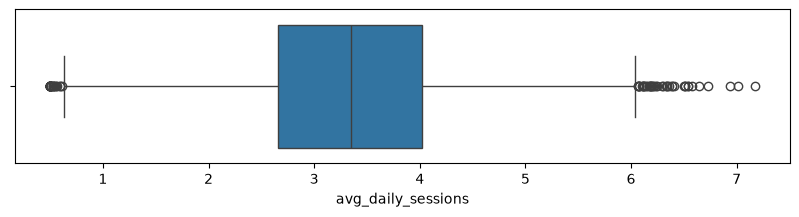

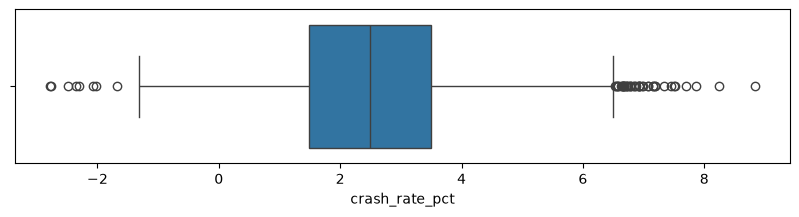

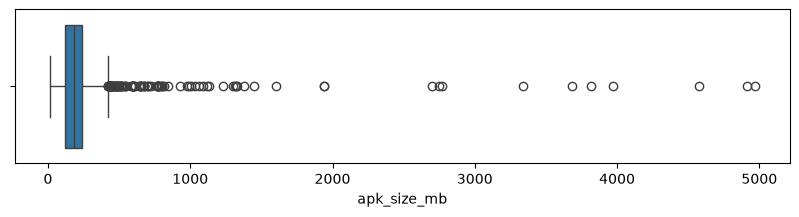

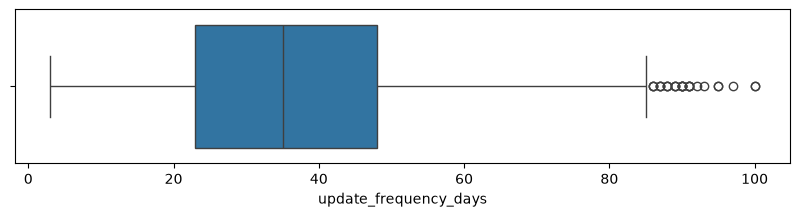

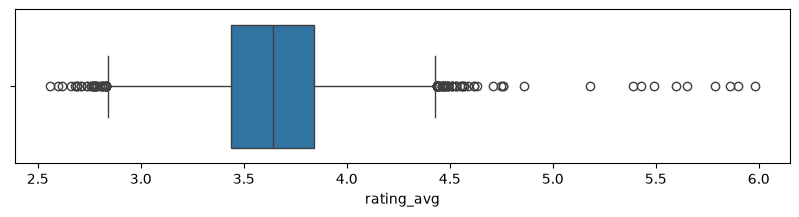

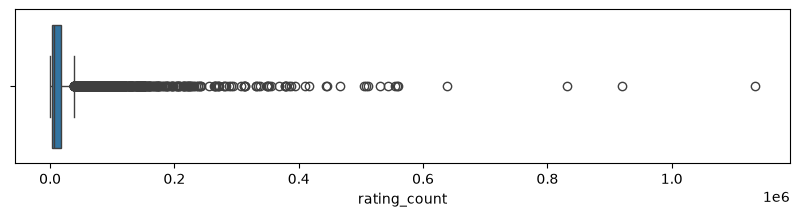

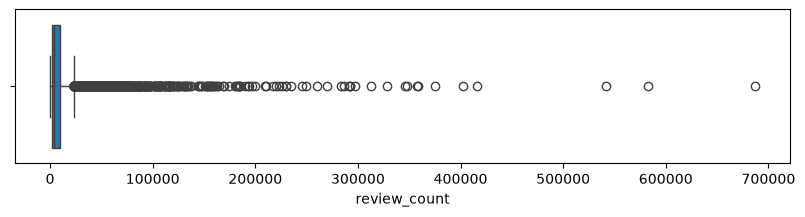

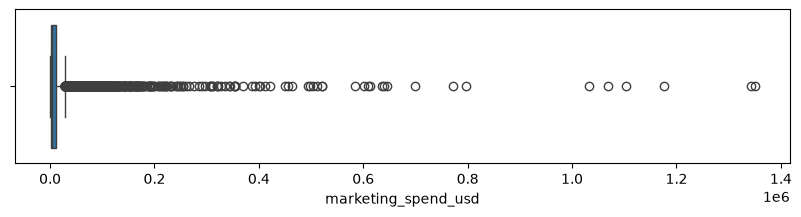

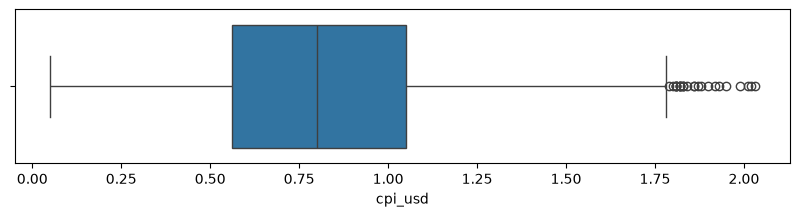

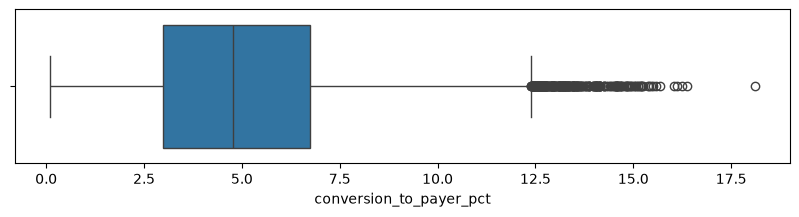

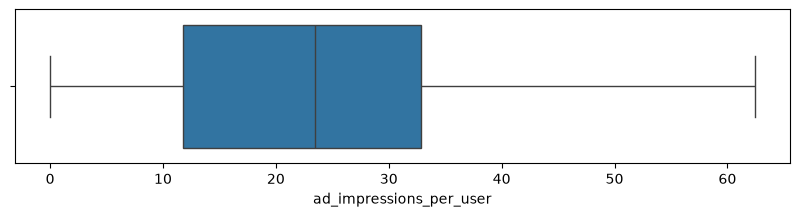

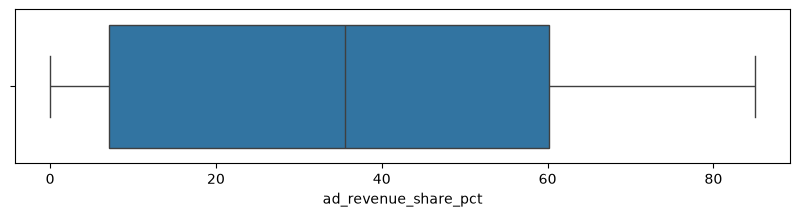

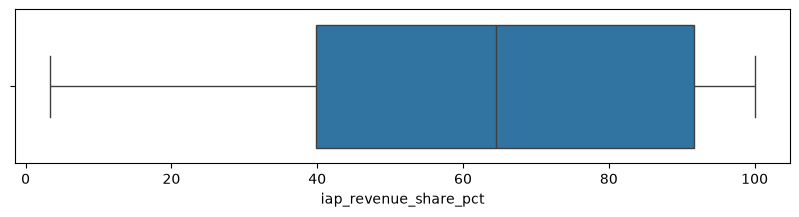

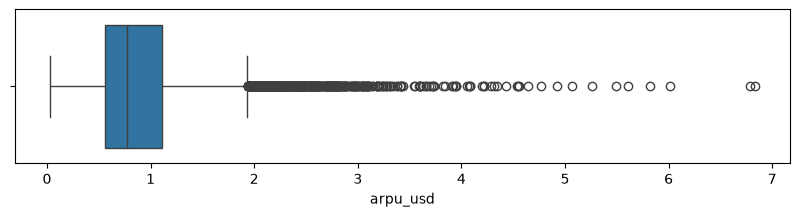

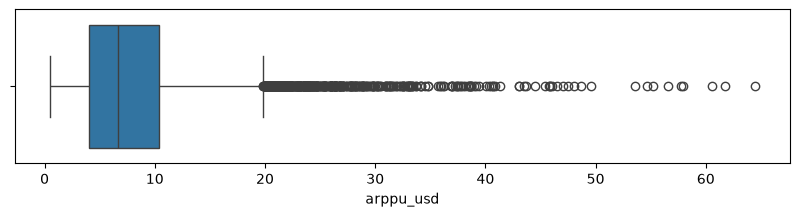

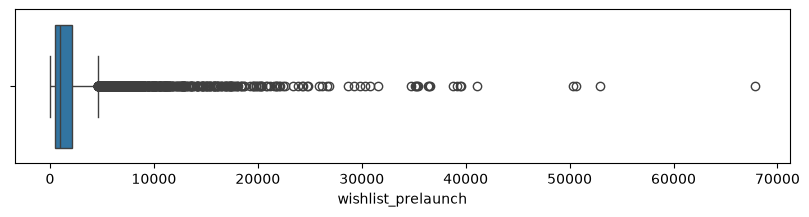

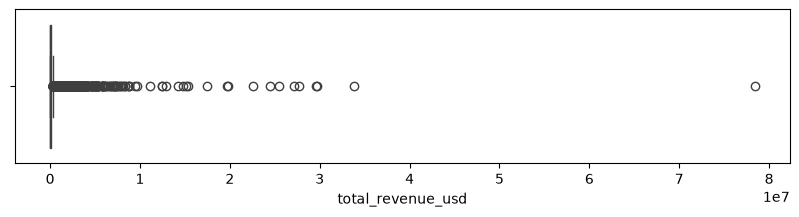

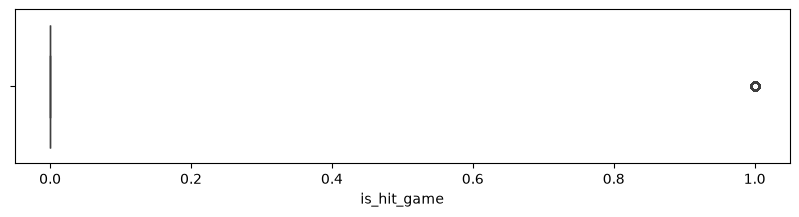

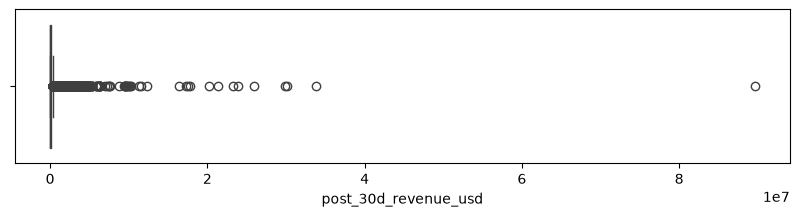

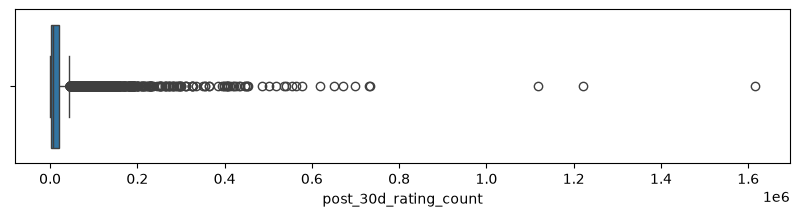

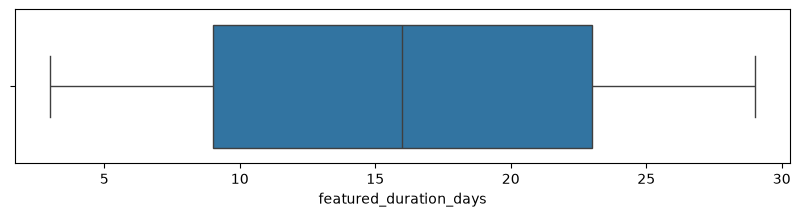

In [7]:
for i in num_cols:
    plt.figure(figsize=(10, 2))
    sns.boxplot(data=df, x=i)
    plt.show()

In [13]:
for col in num_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    IQR = q3 - q1
    
    lb = q1 - (1.5 * IQR)
    ub = q3 + (1.5 * IQR)
    
    outliers = df[(df[col] < lb) | (df[col] > ub)]
    
    print("Column:", col)
    print("Q1:", q1)
    print("Q3:", q3)
    print("IQR:", IQR)
    print("Lower Bound:", lb)
    print("Upper Bound:", ub)
    print("Number of Outliers:", len(outliers))
    print("-" * 50)

Column: game_id
Q1: 2502.25
Q3: 7501.75
IQR: 4999.5
Lower Bound: -4997.0
Upper Bound: 15001.0
Number of Outliers: 0
--------------------------------------------------
Column: price_usd
Q1: 0.0
Q3: 0.0
IQR: 0.0
Lower Bound: 0.0
Upper Bound: 0.0
Number of Outliers: 1987
--------------------------------------------------
Column: downloads
Q1: 46301.0
Q3: 267512.25
IQR: 221211.25
Lower Bound: -285515.875
Upper Bound: 599329.125
Number of Outliers: 1005
--------------------------------------------------
Column: retention_day1_pct
Q1: 23.7
Q3: 36.17
IQR: 12.470000000000002
Lower Bound: 4.994999999999994
Upper Bound: 54.87500000000001
Number of Outliers: 67
--------------------------------------------------
Column: retention_day7_pct
Q1: 12.12
Q3: 20.52
IQR: 8.4
Lower Bound: -0.4800000000000022
Upper Bound: 33.120000000000005
Number of Outliers: 121
--------------------------------------------------
Column: retention_day30_pct
Q1: 5.17
Q3: 10.0
IQR: 4.83
Lower Bound: -2.075
Upper Bound: 17.24

# Missing values

In [8]:
miss_percent = df.isnull().mean()*100
miss_percent

game_id                      0.000000
game_name                    0.000000
developer_name               0.000000
package_name                 0.000000
genre                        0.000000
sub_genre                    0.000000
monetization_model           0.000000
contains_ads                 0.000000
has_in_app_purchases         0.000000
multiplayer_support         40.059113
age_rating                   0.000000
art_style                    0.000000
engine_used                  0.000000
region_focus                 0.000000
publisher_tier               0.000000
event_theme                 75.684729
release_date                 0.000000
soft_launch_date             9.970443
last_update_date             0.000000
was_featured_on_store        0.000000
featured_start_date         67.044335
featured_end_date           67.073892
price_usd                    0.000000
downloads                    0.000000
retention_day1_pct           0.000000
retention_day7_pct           0.000000
retention_da

In [9]:
df[num_cols].median()

game_id                      4997.500
price_usd                       0.000
downloads                  110428.500
retention_day1_pct             29.550
retention_day7_pct             15.900
retention_day30_pct             7.280
active_users_30d             7482.500
avg_session_minutes            19.570
avg_daily_sessions              3.350
crash_rate_pct                  2.495
apk_size_mb                   180.100
update_frequency_days          35.000
rating_avg                      3.640
rating_count                 6807.500
review_count                 4030.000
marketing_spend_usd          4160.800
cpi_usd                         0.800
conversion_to_payer_pct         4.780
ad_impressions_per_user        23.490
ad_revenue_share_pct           35.555
iap_revenue_share_pct          64.535
arpu_usd                        0.770
arppu_usd                       6.685
wishlist_prelaunch            974.000
total_revenue_usd           42567.830
is_hit_game                     0.000
post_30d_rev

In [10]:
df[num_cols] = df[num_cols].fillna(df[num_cols].median())

df

,game_id,game_name,developer_name,package_name,genre,sub_genre,monetization_model,contains_ads,has_in_app_purchases,multiplayer_support,...,has_seasonal_event,cross_platform_available,cloud_save_support,is_hit_game,post_30d_revenue_usd,post_30d_rating_count,featured_duration_days,store_platform,country_code_primary,row_checksum_id
0,622,Game_622_Arena,Studio_205,com.studio1664.game622,Casual,Party Game,Freemium,Yes,Yes,NaN,...,False,True,True,0,9963.75,6328,16.0,Android,IN,CHK_100621
1,4386,Game_4386_Rush,Studio_923,com.studio1615.game4386,RPG,Idle RPG,Free,Yes,No,Online,...,False,True,False,0,17880.43,9346,16.0,Android,IN,CHK_104385
2,6795,Game_6795_Tycoon,Studio_921,com.studio44.game6795,RPG,Idle RPG,Free,Yes,No,NaN,...,True,False,False,0,6060.03,4096,7.0,Android,BR,CHK_106794
3,4563,Game_4563_Quest,Studio_1873,com.studio1353.game4563,Casual,Idle Clicker,Paid,No,Yes,NaN,...,False,False,False,0,816621.72,12402,16.0,Android,US,CHK_104562
4,9265,Game_9265_Legends,Studio_1608,com.studio1308.game9265,RPG,MMORPG,Free,Yes,No,NaN,...,True,False,True,0,159839.20,7517,16.0,Android,IN,CHK_109264
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10145,5735,Game_5735_Legends,Studio_1081,com.studio774.game5735,Action,Endless Runner,Freemium,Yes,No,NaN,...,False,False,True,0,841316.57,156319,12.0,Android,IN,CHK_105734
10146,5192,Game_5192_Arena,Studio_1591,com.studio2181.game5192,RPG,Turn-Based,Free,Yes,Yes,NaN,...,False,True,False,0,172807.46,49521,16.0,Android,IN,CHK_105191
10147,5391,Game_5391_Tycoon,Studio_1105,com.studio1086.game5391,Sports,Cricket,Free,Yes,Yes,Online,...,False,True,True,0,43861.19,3539,16.0,Android,IN,CHK_105390
10148,861,Game_861_Legends,Studio_1864,com.studio1402.game861,Casual,Hypercasual,Free,Yes,No,NaN,...,False,False,False,0,6529.90,3189,16.0,Android,IN,CHK_100860


In [11]:
num_cols = df.select_dtypes(include='number').columns
df[num_cols] = df[num_cols].fillna(df[num_cols].median())
cat_cols = df.select_dtypes(include='object').columns
for col in cat_cols:
    df[col] = df[col].fillna('Unknown')

C:\Users\MEGHANA\AppData\Local\Temp\ipykernel_6320\1760662319.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include='object').columns


In [12]:
df.isnull().sum()

game_id                     0
game_name                   0
developer_name              0
package_name                0
genre                       0
sub_genre                   0
monetization_model          0
contains_ads                0
has_in_app_purchases        0
multiplayer_support         0
age_rating                  0
art_style                   0
engine_used                 0
region_focus                0
publisher_tier              0
event_theme                 0
release_date                0
soft_launch_date            0
last_update_date            0
was_featured_on_store       0
featured_start_date         0
featured_end_date           0
price_usd                   0
downloads                   0
retention_day1_pct          0
retention_day7_pct          0
retention_day30_pct         0
active_users_30d            0
avg_session_minutes         0
avg_daily_sessions          0
crash_rate_pct              0
apk_size_mb                 0
update_frequency_days       0
rating_avg

In [14]:
import feature_engine

In [15]:
from feature_engine.outliers import Winsorizer

In [18]:
win_obj = Winsorizer(capping_method = 'iqr' , tail = 'both')

win_obj

,capping_method,'iqr'
,tail,'both'
,fold,'auto'
,add_indicators,False
,variables,None
,missing_values,'raise'


In [21]:
num_cols = df.select_dtypes(include='number').columns

Q1 = df[num_cols].quantile(0.25)
Q3 = df[num_cols].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

df[num_cols] = df[num_cols].clip(lower=lower, upper=upper, axis=1)

In [22]:
outliers = (
    (df[num_cols] < lower) |
    (df[num_cols] > upper)
)

outliers.sum()

game_id                    0
price_usd                  0
downloads                  0
retention_day1_pct         0
retention_day7_pct         0
retention_day30_pct        0
active_users_30d           0
avg_session_minutes        0
avg_daily_sessions         0
crash_rate_pct             0
apk_size_mb                0
update_frequency_days      0
rating_avg                 0
rating_count               0
review_count               0
marketing_spend_usd        0
cpi_usd                    0
conversion_to_payer_pct    0
ad_impressions_per_user    0
ad_revenue_share_pct       0
iap_revenue_share_pct      0
arpu_usd                   0
arppu_usd                  0
wishlist_prelaunch         0
total_revenue_usd          0
is_hit_game                0
post_30d_revenue_usd       0
post_30d_rating_count      0
featured_duration_days     0
dtype: int64

# The Cleaned Data

In [23]:
df

,game_id,game_name,developer_name,package_name,genre,sub_genre,monetization_model,contains_ads,has_in_app_purchases,multiplayer_support,...,has_seasonal_event,cross_platform_available,cloud_save_support,is_hit_game,post_30d_revenue_usd,post_30d_rating_count,featured_duration_days,store_platform,country_code_primary,row_checksum_id
0,622,Game_622_Arena,Studio_205,com.studio1664.game622,Casual,Party Game,Freemium,Yes,Yes,NaN,...,False,True,True,0,9963.7500,6328.000,16.0,Android,IN,CHK_100621
1,4386,Game_4386_Rush,Studio_923,com.studio1615.game4386,RPG,Idle RPG,Free,Yes,No,Online,...,False,True,False,0,17880.4300,9346.000,16.0,Android,IN,CHK_104385
2,6795,Game_6795_Tycoon,Studio_921,com.studio44.game6795,RPG,Idle RPG,Free,Yes,No,NaN,...,True,False,False,0,6060.0300,4096.000,16.0,Android,BR,CHK_106794
3,4563,Game_4563_Quest,Studio_1873,com.studio1353.game4563,Casual,Idle Clicker,Paid,No,Yes,NaN,...,False,False,False,0,322991.8625,12402.000,16.0,Android,US,CHK_104562
4,9265,Game_9265_Legends,Studio_1608,com.studio1308.game9265,RPG,MMORPG,Free,Yes,No,NaN,...,True,False,True,0,159839.2000,7517.000,16.0,Android,IN,CHK_109264
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10145,5735,Game_5735_Legends,Studio_1081,com.studio774.game5735,Action,Endless Runner,Freemium,Yes,No,NaN,...,False,False,True,0,322991.8625,44466.625,16.0,Android,IN,CHK_105734
10146,5192,Game_5192_Arena,Studio_1591,com.studio2181.game5192,RPG,Turn-Based,Free,Yes,Yes,NaN,...,False,True,False,0,172807.4600,44466.625,16.0,Android,IN,CHK_105191
10147,5391,Game_5391_Tycoon,Studio_1105,com.studio1086.game5391,Sports,Cricket,Free,Yes,Yes,Online,...,False,True,True,0,43861.1900,3539.000,16.0,Android,IN,CHK_105390
10148,861,Game_861_Legends,Studio_1864,com.studio1402.game861,Casual,Hypercasual,Free,Yes,No,NaN,...,False,False,False,0,6529.9000,3189.000,16.0,Android,IN,CHK_100860


# There is Inconsistent/ Nosiy Data

In [5]:
for col in df.select_dtypes(include='object').columns:
    df[col] = df[col].str.strip()
    df[col] = df[col].str.lower()

print("Inconsistent categorical data cleaned successfully.")

Inconsistent categorical data cleaned successfully.


C:\Users\MEGHANA\AppData\Local\Temp\ipykernel_6320\639268930.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include='object').columns:


In [6]:
for col in df.select_dtypes(include='object').columns:
    print("\n", col)
    print(df[col].unique())
    print("-"*60)


 game_name
<StringArray>
[   'game_622_arena',    'game_4386_rush',  'game_6795_tycoon',
   'game_4563_quest', 'game_9265_legends',    'game_3133_rush',
   'game_8711_world',    'game_5738_dash',    'game_7783_dash',
   'game_6504_world',
 ...
 'game_8323_legends',    'game_5579_saga',    'game_4427_rush',
     'game_467_dash', 'game_6266_legends', 'game_5735_legends',
   'game_5192_arena',  'game_5391_tycoon',  'game_861_legends',
 'game_7271_legends']
Length: 10000, dtype: str
------------------------------------------------------------

 developer_name
<StringArray>
[   'studio_205',    'studio_923',    'studio_921',   'studio_1873',
   'studio_1608',   'studio_1659',    'studio_820',   'studio_1234',
   'studio_1598',    'studio_596',
 ...
   'studio_1745',    'studio_249',    'studio_625',    'studio_174',
   'studio_1369',    'studio_857',    'studio_380', 'rarestudio_47',
   'studio_1510',    'studio_694']
Length: 2222, dtype: str
-----------------------------------------------

C:\Users\MEGHANA\AppData\Local\Temp\ipykernel_6320\1194427528.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include='object').columns:


# The Cleaned Data

In [13]:
df

,game_id,game_name,developer_name,package_name,genre,sub_genre,monetization_model,contains_ads,has_in_app_purchases,multiplayer_support,...,has_seasonal_event,cross_platform_available,cloud_save_support,is_hit_game,post_30d_revenue_usd,post_30d_rating_count,featured_duration_days,store_platform,country_code_primary,row_checksum_id
0,622,game_622_arena,studio_205,com.studio1664.game622,casual,party game,freemium,yes,yes,Unknown,...,False,True,True,0,9963.75,6328,16.0,android,in,chk_100621
1,4386,game_4386_rush,studio_923,com.studio1615.game4386,rpg,idle rpg,free,yes,no,online,...,False,True,False,0,17880.43,9346,16.0,android,in,chk_104385
2,6795,game_6795_tycoon,studio_921,com.studio44.game6795,rpg,idle rpg,free,yes,no,Unknown,...,True,False,False,0,6060.03,4096,7.0,android,br,chk_106794
3,4563,game_4563_quest,studio_1873,com.studio1353.game4563,casual,idle clicker,paid,no,yes,Unknown,...,False,False,False,0,816621.72,12402,16.0,android,us,chk_104562
4,9265,game_9265_legends,studio_1608,com.studio1308.game9265,rpg,mmorpg,free,yes,no,Unknown,...,True,False,True,0,159839.20,7517,16.0,android,in,chk_109264
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10145,5735,game_5735_legends,studio_1081,com.studio774.game5735,action,endless runner,freemium,yes,no,Unknown,...,False,False,True,0,841316.57,156319,12.0,android,in,chk_105734
10146,5192,game_5192_arena,studio_1591,com.studio2181.game5192,rpg,turn-based,free,yes,yes,Unknown,...,False,True,False,0,172807.46,49521,16.0,android,in,chk_105191
10147,5391,game_5391_tycoon,studio_1105,com.studio1086.game5391,sports,cricket,free,yes,yes,online,...,False,True,True,0,43861.19,3539,16.0,android,in,chk_105390
10148,861,game_861_legends,studio_1864,com.studio1402.game861,casual,hypercasual,free,yes,no,Unknown,...,False,False,False,0,6529.90,3189,16.0,android,in,chk_100860


In [14]:
df.isnull()  

,game_id,game_name,developer_name,package_name,genre,sub_genre,monetization_model,contains_ads,has_in_app_purchases,multiplayer_support,...,has_seasonal_event,cross_platform_available,cloud_save_support,is_hit_game,post_30d_revenue_usd,post_30d_rating_count,featured_duration_days,store_platform,country_code_primary,row_checksum_id
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10145,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
10146,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
10147,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
10148,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


# Data Manipulation

In [29]:
df.columns

Index(['game_id', 'game_name', 'developer_name', 'package_name', 'genre',
       'sub_genre', 'monetization_model', 'contains_ads',
       'has_in_app_purchases', 'multiplayer_support', 'age_rating',
       'art_style', 'engine_used', 'region_focus', 'publisher_tier',
       'event_theme', 'release_date', 'soft_launch_date', 'last_update_date',
       'was_featured_on_store', 'featured_start_date', 'featured_end_date',
       'price_usd', 'downloads', 'retention_day1_pct', 'retention_day7_pct',
       'retention_day30_pct', 'active_users_30d', 'avg_session_minutes',
       'avg_daily_sessions', 'crash_rate_pct', 'apk_size_mb',
       'update_frequency_days', 'rating_avg', 'rating_count', 'review_count',
       'marketing_spend_usd', 'cpi_usd', 'conversion_to_payer_pct',
       'ad_impressions_per_user', 'ad_revenue_share_pct',
       'iap_revenue_share_pct', 'arpu_usd', 'arppu_usd', 'wishlist_prelaunch',
       'total_revenue_usd', 'is_weekend_release', 'has_seasonal_event',
       'cr

In [20]:
# 1. Genre vs Downloads and Rating
# Question: What are the average downloads and ratings for each genre?

genre_data = df.loc[:, ['genre', 'downloads', 'rating_avg']]

genre_result = genre_data.groupby('genre')[['downloads', 'rating_avg']].mean()

print("Genre-wise Average Downloads and Rating")
print(genre_result) 

Genre-wise Average Downloads and Rating
                downloads  rating_avg
genre                                
Action      327756.254525    3.642432
Casual      392882.521600    3.646944
Puzzle      313519.737844    3.648510
RPG         382941.574450    3.635863
Racing      201907.242134    3.639179
Simulation  245112.908708    3.646713
Sports      242836.985255    3.636555
Strategy    305297.306270    3.633730


In [21]:
# 2. Monetization Model vs Downloads
# Question: What are the average downloads and revenue for each monetization model?

monetization_data = df.iloc[:, [
    df.columns.get_loc('monetization_model'),
    df.columns.get_loc('downloads'),
    df.columns.get_loc('total_revenue_usd')
]]

monetization_result = monetization_data.groupby('monetization_model')[
    ['downloads', 'total_revenue_usd']
].mean()

print("Monetization Model-wise Average Downloads and Revenue")
print(monetization_result)

Monetization Model-wise Average Downloads and Revenue
                        downloads  total_revenue_usd
monetization_model                                  
Free                312991.797715       97206.526618
Freemium            332587.070509      130156.461420
Paid                310664.161182      930079.852139
Subscription        276002.093686      881352.002677


In [22]:
# 3. Age Rating vs Game Performance
# Question: How does age rating relate to downloads and rating?

age_data = df.loc[:, ['age_rating', 'downloads', 'rating_avg']]

age_result = age_data.groupby('age_rating')[['downloads', 'rating_avg']].mean()

print("Age Rating-wise Game Performance")
print(age_result)

Age Rating-wise Game Performance
                downloads  rating_avg
age_rating                           
Everyone    336407.720071    3.643989
Mature 17+  292872.022094    3.645264
Teen        300704.126761    3.638390


In [23]:
# 4. Genre vs Monetization Model
# Question: How many games are available under each genre and monetization model?

genre_monetization = pd.crosstab(
    df['genre'],
    df['monetization_model']
)

print("Genre vs Monetization Model")
print(genre_monetization)

Genre vs Monetization Model
monetization_model  Free  Freemium  Paid  Subscription
genre                                                 
Action               646       765   257           100
Casual               628       878   271            98
Puzzle               678       846   270            98
RPG                  434       520   183            45
Racing               264       326   109            32
Simulation           233       328   116            35
Sports               276       340   105            25
Strategy             430       578   178            58


In [24]:
# 5. Genre vs Multiplayer Support
# Question: How is multiplayer support distributed across different genres?

genre_multiplayer = pd.crosstab(
    df['genre'],
    df['multiplayer_support']
)

print("Genre vs Multiplayer Support")
print(genre_multiplayer)

Genre vs Multiplayer Support
multiplayer_support  Both  Local  Online
genre                                   
Action                280    171     624
Casual                252    206     694
Puzzle                287    176     658
RPG                   201    126     399
Racing                109     82     257
Simulation            110     75     219
Sports                112     64     252
Strategy              213    109     408


In [25]:
# 6. Age Rating vs Monetization Model
# Question: How are monetization models distributed across age ratings?

age_monetization = pd.crosstab(
    df['age_rating'],
    df['monetization_model']
)

print("Age Rating vs Monetization Model")
print(age_monetization)

Age Rating vs Monetization Model
monetization_model  Free  Freemium  Paid  Subscription
age_rating                                            
Everyone            2029      2544   805           252
Mature 17+           381       441   170            49
Teen                1179      1596   514           190


In [26]:
# 7. Genre vs Average Downloads
# Question: What is the average number of downloads for each genre?

genre_downloads = df.loc[:, ['genre', 'downloads']]

genre_download_pivot = genre_downloads.pivot_table(
    index='genre',
    values='downloads',
    aggfunc='mean'
)

print("Genre vs Average Downloads")
print(genre_download_pivot)

Genre vs Average Downloads
                downloads
genre                    
Action      327756.254525
Casual      392882.521600
Puzzle      313519.737844
RPG         382941.574450
Racing      201907.242134
Simulation  245112.908708
Sports      242836.985255
Strategy    305297.306270


In [27]:
# 8. Genre and Monetization vs Downloads
# Question: How do average downloads vary by genre and monetization model?

genre_model_data = df.iloc[:, [
    df.columns.get_loc('genre'),
    df.columns.get_loc('monetization_model'),
    df.columns.get_loc('downloads')
]]

genre_model_pivot = genre_model_data.pivot_table(
    index='genre',
    columns='monetization_model',
    values='downloads',
    aggfunc='mean'
)

print("Genre + Monetization Model vs Average Downloads")
print(genre_model_pivot)

Genre + Monetization Model vs Average Downloads
monetization_model           Free       Freemium           Paid   Subscription
genre                                                                         
Action              328988.041796  341183.467974  285611.178988  325393.570000
Casual              408056.842357  386675.528474  366327.162362  424686.285714
Puzzle              347704.414454  296037.444444  306420.774074  247494.530612
RPG                 318157.709677  385179.842308  539047.240437  347051.822222
Racing              233038.215909  148396.512270  305993.348624  135673.968750
Simulation          220314.094421  304656.615854  166440.318966  112936.000000
Sports              181875.652174  299759.067647  240912.857143  149791.120000
Strategy            273638.600000  384275.070934  171723.292135  162888.172414


In [28]:
# 9. Engine Used vs Game Performance
# Question: What are the average downloads, rating and crash rate for each game engine?

engine_data = df.loc[:, [
    'engine_used',
    'downloads',
    'rating_avg',
    'crash_rate_pct'
]]

engine_result = engine_data.groupby('engine_used')[
    ['downloads', 'rating_avg', 'crash_rate_pct']
].mean()

print("Engine-wise Game Performance")
print(engine_result)

Engine-wise Game Performance
                 downloads  rating_avg  crash_rate_pct
engine_used                                           
Custom       256744.832983    3.634191        2.605410
Godot        301766.992193    3.633787        2.596662
Unity        323835.688478    3.646050        2.505113
Unreal       378981.531096    3.637236        2.479052


In [29]:
# 10. Region Focus vs Downloads and Revenue
# Question: What are the average downloads and revenue for each region focus?

region_data = df.iloc[:, [
    df.columns.get_loc('region_focus'),
    df.columns.get_loc('downloads'),
    df.columns.get_loc('total_revenue_usd')
]]

region_result = region_data.groupby('region_focus')[
    ['downloads', 'total_revenue_usd']
].mean()

print("Region-wise Average Downloads and Revenue")
print(region_result)

Region-wise Average Downloads and Revenue
                  downloads  total_revenue_usd
region_focus                                  
Europe        321224.361325      278617.393010
Global        369390.347045      307575.781305
India         360483.423571      341174.992387
LATAM         280446.886726      208620.696956
SEA           276560.521018      234285.062339
US            308201.823242      260943.368962


In [30]:
# 11. Art Style vs Rating
# Question: What is the average rating and average downloads for each art style?

art_data = df.loc[:, [
    'art_style',
    'rating_avg',
    'downloads'
]]

art_result = art_data.groupby('art_style')[
    ['rating_avg', 'downloads']
].mean()

print("Art Style-wise Rating and Downloads")
print(art_result)

Art Style-wise Rating and Downloads
              rating_avg      downloads
art_style                              
2D Cartoon      3.647430  353672.432659
3D Realistic    3.642460  304848.494059
Anime           3.633575  325997.114327
Minimalist      3.637249  289957.724855
Pixel           3.650866  324613.824669


In [31]:
# 12. Multiplayer Support vs Downloads
# Question: What are the average downloads and revenue for each multiplayer type?

multiplayer_data = df.iloc[:, [
    df.columns.get_loc('multiplayer_support'),
    df.columns.get_loc('downloads'),
    df.columns.get_loc('total_revenue_usd')
]]

multiplayer_result = multiplayer_data.groupby(
    'multiplayer_support'
)[['downloads', 'total_revenue_usd']].mean()

print("Multiplayer Support-wise Downloads and Revenue")
print(multiplayer_result)

Multiplayer Support-wise Downloads and Revenue
                         downloads  total_revenue_usd
multiplayer_support                                  
Both                 291945.556905      234720.642708
Local                337797.952428      312297.739107
Online               327254.885788      271682.832418


In [32]:
# 13. Using AT
# Question: What is the rating of a particular game?

game_rating = df.loc[:, ['game_name', 'rating_avg']]

rating_value = game_rating.at[0, 'rating_avg']

print("Rating of the first game:")
print(rating_value)

Rating of the first game:
3.48


In [33]:
# 14. Using IAT
# Question: What is the download count of the first game?

game_downloads = df.iloc[:, [
    df.columns.get_loc('game_name'),
    df.columns.get_loc('downloads')
]]

download_value = game_downloads.iat[0, 1]

print("Downloads of the first game:")
print(download_value)

Downloads of the first game:
70113


In [34]:
# 15. Fancy Indexing
# Question: Select multiple rows and columns to analyze
# game genre, downloads, rating and monetization model.

fancy_data = df.iloc[
    [0, 10, 20, 30, 40],
    [df.columns.get_loc('genre'),
     df.columns.get_loc('downloads'),
     df.columns.get_loc('rating_avg'),
     df.columns.get_loc('monetization_model')]
]

print("Selected Games using Fancy Indexing")
print(fancy_data)

Selected Games using Fancy Indexing
         genre  downloads  rating_avg monetization_model
0       Casual      70113        3.48           Freemium
10      Casual      31194        3.64               Free
20         RPG      66534        3.44               Free
30  Simulation      55466        3.98               Free
40         RPG     720955        3.25       Subscription


# Data Visualisation

## Univariate Analysis
* Numerical Columns and Categorical Columns

In [8]:
# Remove outliers from Downloads using IQR method

Q1 = df['downloads'].quantile(0.25)
Q3 = df['downloads'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

df['downloads'] = df['downloads'].clip(lower=lower_limit, upper=upper_limit)

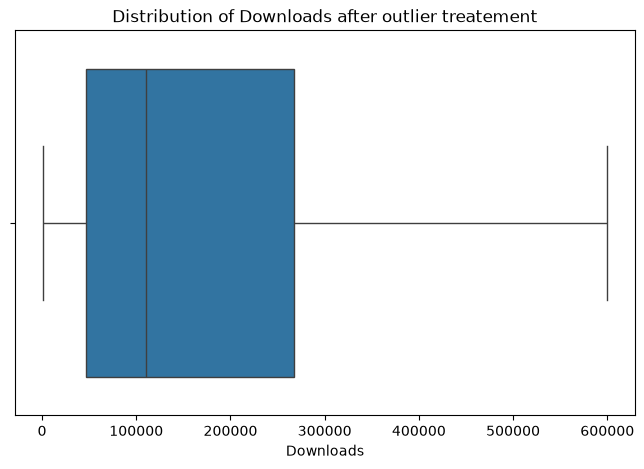

In [10]:
plt.figure(figsize=(8,5))
sns.boxplot(x=df['downloads'])
plt.title('Distribution of Downloads after outlier treatement')
plt.xlabel('Downloads')
plt.show()

## Insights :

* Most games have relatively lower downloads.
* Several high-value outliers are present.
* A few games have exceptionally high downloads.
* The distribution is right-skewed

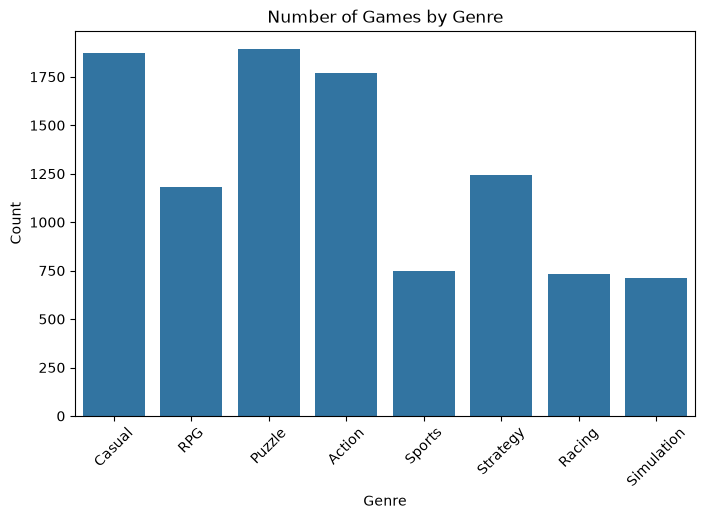

In [22]:
plt.figure(figsize=(8,5))
sns.countplot(x=df['genre'])
plt.title('Number of Games by Genre')
plt.xlabel('Genre')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.show()

## Insights :

* The number of games varies across genres.
* Some genres have more games than others.
* The least represented genres have fewer games.
* The plot shows the distribution of games across genres.

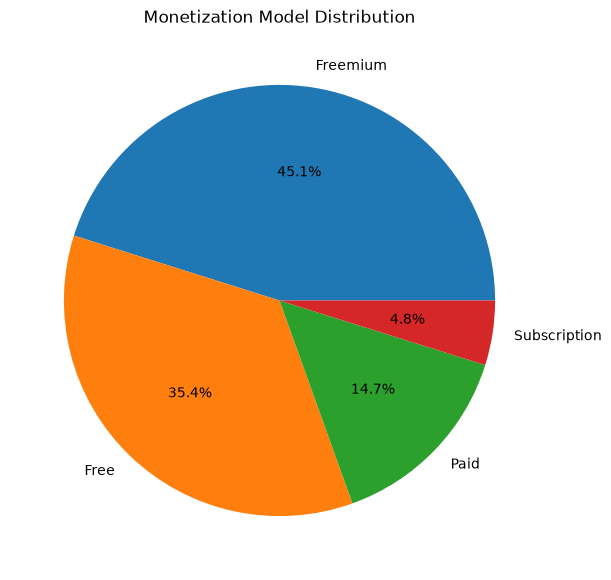

In [23]:
plt.figure(figsize=(7,7))
df['monetization_model'].value_counts().plot.pie(
    autopct='%1.1f%%'
)
plt.title('Monetization Model Distribution')
plt.ylabel('')
plt.show()

## Insights :

* Different monetization models are present.
* One or more models account for a larger share of games.
* Some models have a smaller share.
* The chart shows the overall monetization distribution.

In [11]:
# Remove outliers from Rating using IQR method

Q1 = df['rating_avg'].quantile(0.25)
Q3 = df['rating_avg'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

df['rating_avg'] = df['rating_avg'].clip(lower=lower_limit, upper=upper_limit)

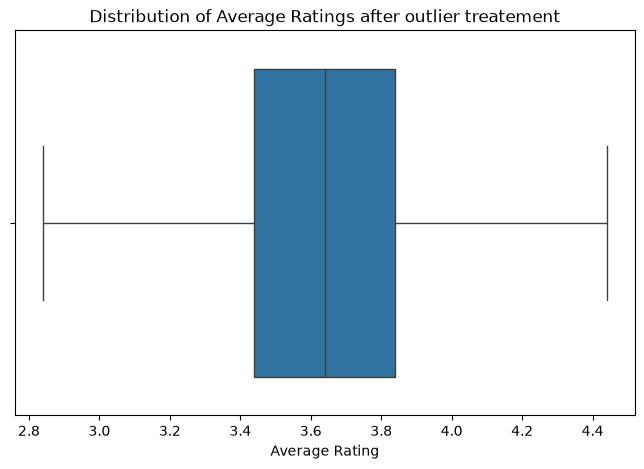

In [13]:
plt.figure(figsize=(8,5))
sns.boxplot(x=df['rating_avg'])
plt.title('Distribution of Average Ratings after outlier treatement')
plt.xlabel('Average Rating')
plt.show()

## Insights :

* Most ratings are concentrated within a particular range.
* The ratings show some variation across games.
* Any points outside the main range indicate potential outliers.
* The boxplot shows the overall spread of game ratings.

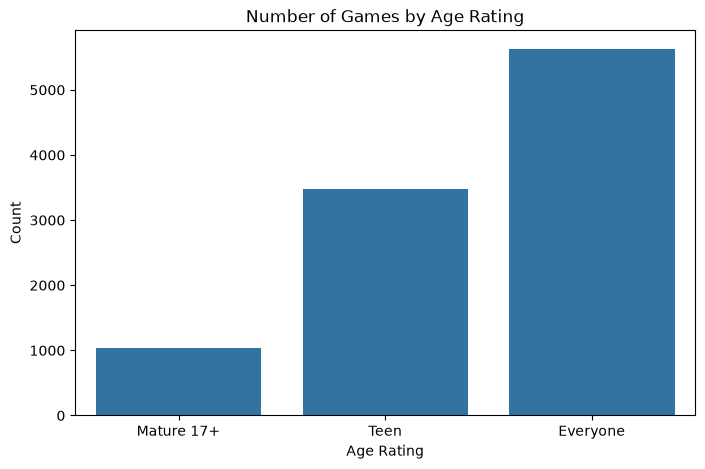

In [25]:
plt.figure(figsize=(8,5))
sns.countplot(x=df['age_rating'])
plt.title('Number of Games by Age Rating')
plt.xlabel('Age Rating')
plt.ylabel('Count')
plt.show()

## Insights :

* Games are distributed across different age-rating categories.
* Some age-rating categories contain more games.
* Some categories have relatively fewer games.
* The plot shows the age-rating distribution of the dataset.

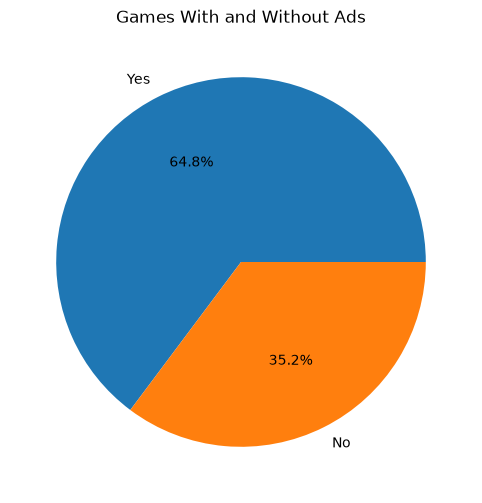

In [26]:
plt.figure(figsize=(6,6))
df['contains_ads'].value_counts().plot.pie(
    autopct='%1.1f%%'
)
plt.title('Games With and Without Ads')
plt.ylabel('')
plt.show()

## Insights :

* The dataset contains games with and without advertisements.
* One category may represent a larger proportion of games.
* The smaller category represents fewer games.
* The chart shows the overall distribution of advertisements.

## Bi-Variate Analysis
* Numerical vs Numerical / Categorical vs Categorical / Numercial vs Categorical

In [14]:
# Remove outliers from Rating using IQR method

Q1 = df['rating_avg'].quantile(0.25)
Q3 = df['rating_avg'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

df['rating_avg'] = df['rating_avg'].clip(
    lower=lower_limit,
    upper=upper_limit
)

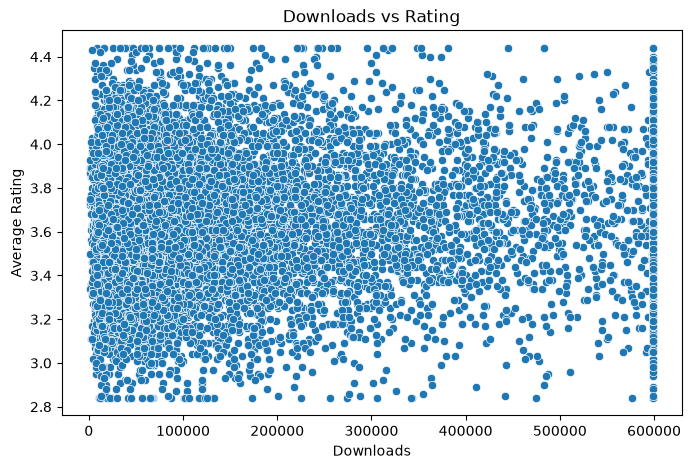

In [15]:
plt.figure(figsize=(8,5))
sns.scatterplot(x='downloads', y='rating_avg', data=df)
plt.title('Downloads vs Rating')
plt.xlabel('Downloads')
plt.ylabel('Average Rating')
plt.show()

## Insights : 

* Downloads vary across different ratings.
* Highly rated games can have different download levels.
* No clear strong pattern is visible from the plot alone.
* Downloads are widely spread.

In [23]:
# Remove outliers from Downloads within each Monetization Model

Q1 = df.groupby('monetization_model')['downloads'].transform('quantile', 0.25)
Q3 = df.groupby('monetization_model')['downloads'].transform('quantile', 0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

df['downloads'] = df['downloads'].clip(lower=lower_limit, upper=upper_limit)

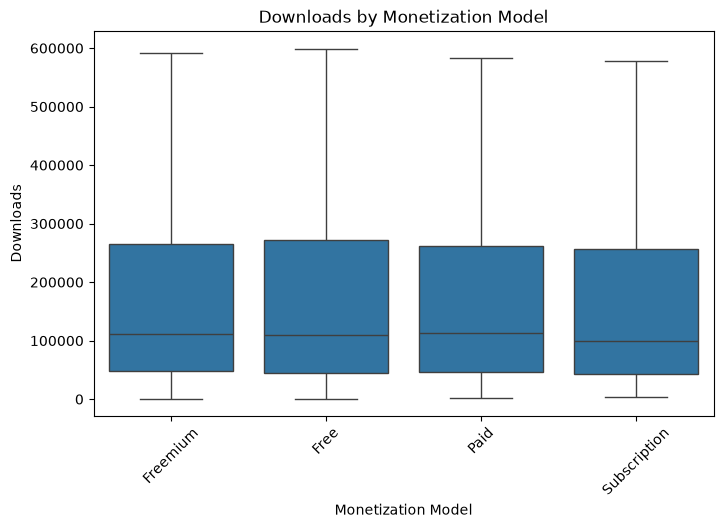

In [24]:
plt.figure(figsize=(8,5))
sns.boxplot(x='monetization_model', y='downloads', data=df)
plt.title('Downloads by Monetization Model')
plt.xlabel('Monetization Model')
plt.ylabel('Downloads')
plt.xticks(rotation=45)
plt.show()

## Insights :

* Download distributions differ across monetization models.
* Some models show higher download ranges.
* Outliers are visible in some categories.
* Downloads have considerable variation within categories.

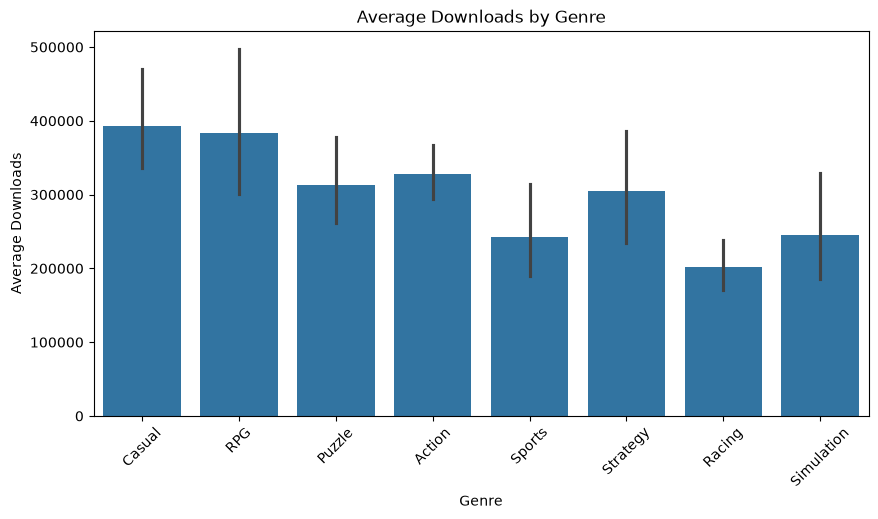

In [49]:
plt.figure(figsize=(10,5))
sns.barplot(x='genre', y='downloads', data=df, estimator='mean')
plt.title('Average Downloads by Genre')
plt.xlabel('Genre')
plt.ylabel('Average Downloads')
plt.xticks(rotation=45)
plt.show()

## Insights :

* Average downloads differ across genres.
* Some genres have higher average downloads.
* Some genres have lower average downloads.
* Genre-wise popularity varies in the dataset

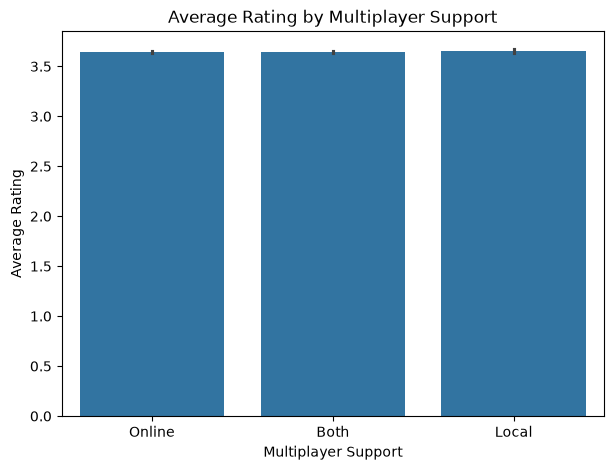

In [50]:
plt.figure(figsize=(7,5))
sns.barplot(x='multiplayer_support', y='rating_avg', data=df, estimator='mean')
plt.title('Average Rating by Multiplayer Support')
plt.xlabel('Multiplayer Support')
plt.ylabel('Average Rating')
plt.show()

## Insights :

* Average ratings differ between multiplayer categories.
* Multiplayer-supported games have a different average rating from others.
* Rating variation exists between the categories.
* This allows comparison of ratings based on multiplayer support.

In [25]:
# Remove outliers from Downloads within each Age Rating

Q1 = df.groupby('age_rating')['downloads'].transform('quantile', 0.25)
Q3 = df.groupby('age_rating')['downloads'].transform('quantile', 0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

df['downloads'] = df['downloads'].clip(
    lower=lower_limit,
    upper=upper_limit
)

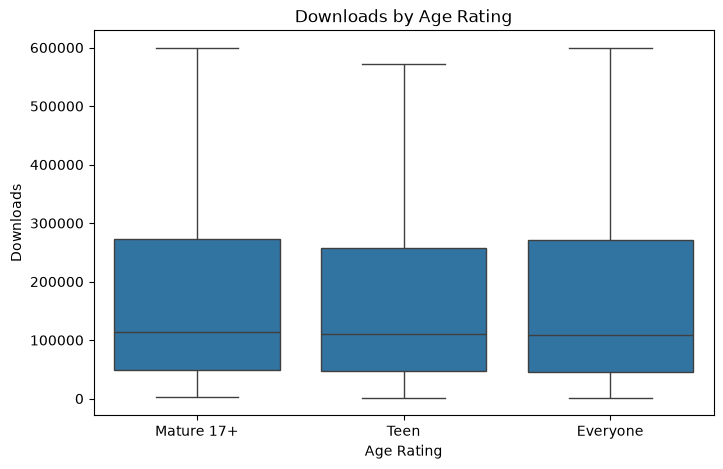

In [26]:
plt.figure(figsize=(8,5))
sns.boxplot(x='age_rating', y='downloads', data=df)
plt.title('Downloads by Age Rating')
plt.xlabel('Age Rating')
plt.ylabel('Downloads')
plt.show()

## Insights :

* Download distributions vary across age-rating categories.
* Some categories have higher download ranges.
* Outliers may appear in certain categories.
* The spread of downloads differs between age-rating groups.

In [27]:
# Remove downloads outliers within each genre

Q1 = df.groupby('genre')['downloads'].transform('quantile', 0.25)
Q3 = df.groupby('genre')['downloads'].transform('quantile', 0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

df['downloads'] = df['downloads'].clip(
    lower=lower_limit,
    upper=upper_limit
)

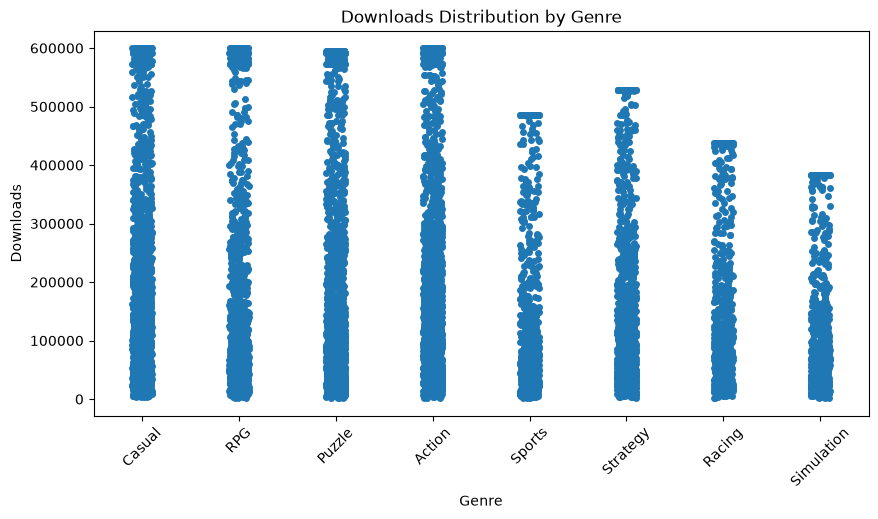

In [28]:
plt.figure(figsize=(10,5))
sns.stripplot(x='genre', y='downloads', data=df)
plt.title('Downloads Distribution by Genre')
plt.xlabel('Genre')
plt.ylabel('Downloads')
plt.xticks(rotation=45)
plt.show()

## Insights :

* Downloads are widely scattered across genres.
* Some genres show greater variation in downloads.
* High-download games appear as separated points.
* The plot shows the distribution of individual games within each genre.

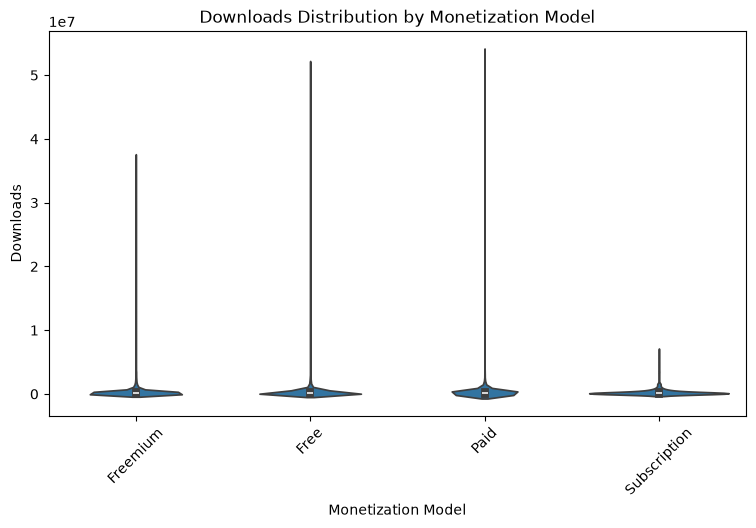

In [53]:
plt.figure(figsize=(9,5))
sns.violinplot(x='monetization_model', y='downloads', data=df)
plt.title('Downloads Distribution by Monetization Model')
plt.xlabel('Monetization Model')
plt.ylabel('Downloads')
plt.xticks(rotation=45)
plt.show()

## Insights

* Download distributions differ across monetization models.
* Some categories have greater concentration of downloads.
* The width of the violins shows where downloads are more concentrated.
* Some categories may contain extreme download values.

## Multi Variate Analysis
* HeatMap / Pair plot / Joint plot

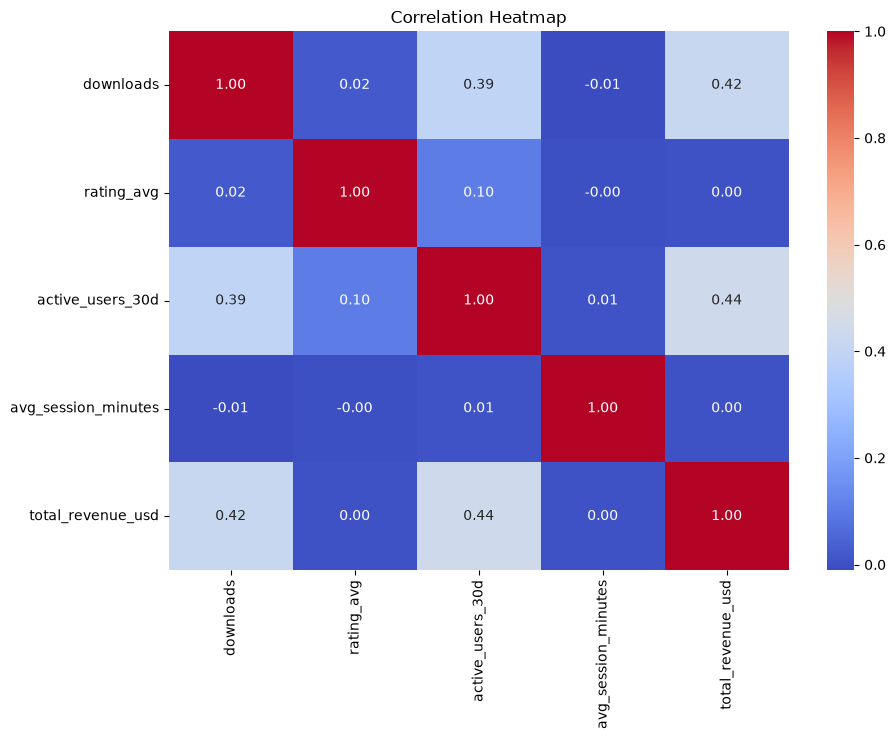

In [4]:
plt.figure(figsize=(10,7))

corr = df[['downloads', 'rating_avg',
           'active_users_30d', 'avg_session_minutes',
           'total_revenue_usd']].corr()

sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

## Insights :

* Downloads and active users show a relationship.
* Downloads and total revenue are related.
* Rating has weaker relationships with some variables.
* Price shows different levels of correlation with downloads and revenue.

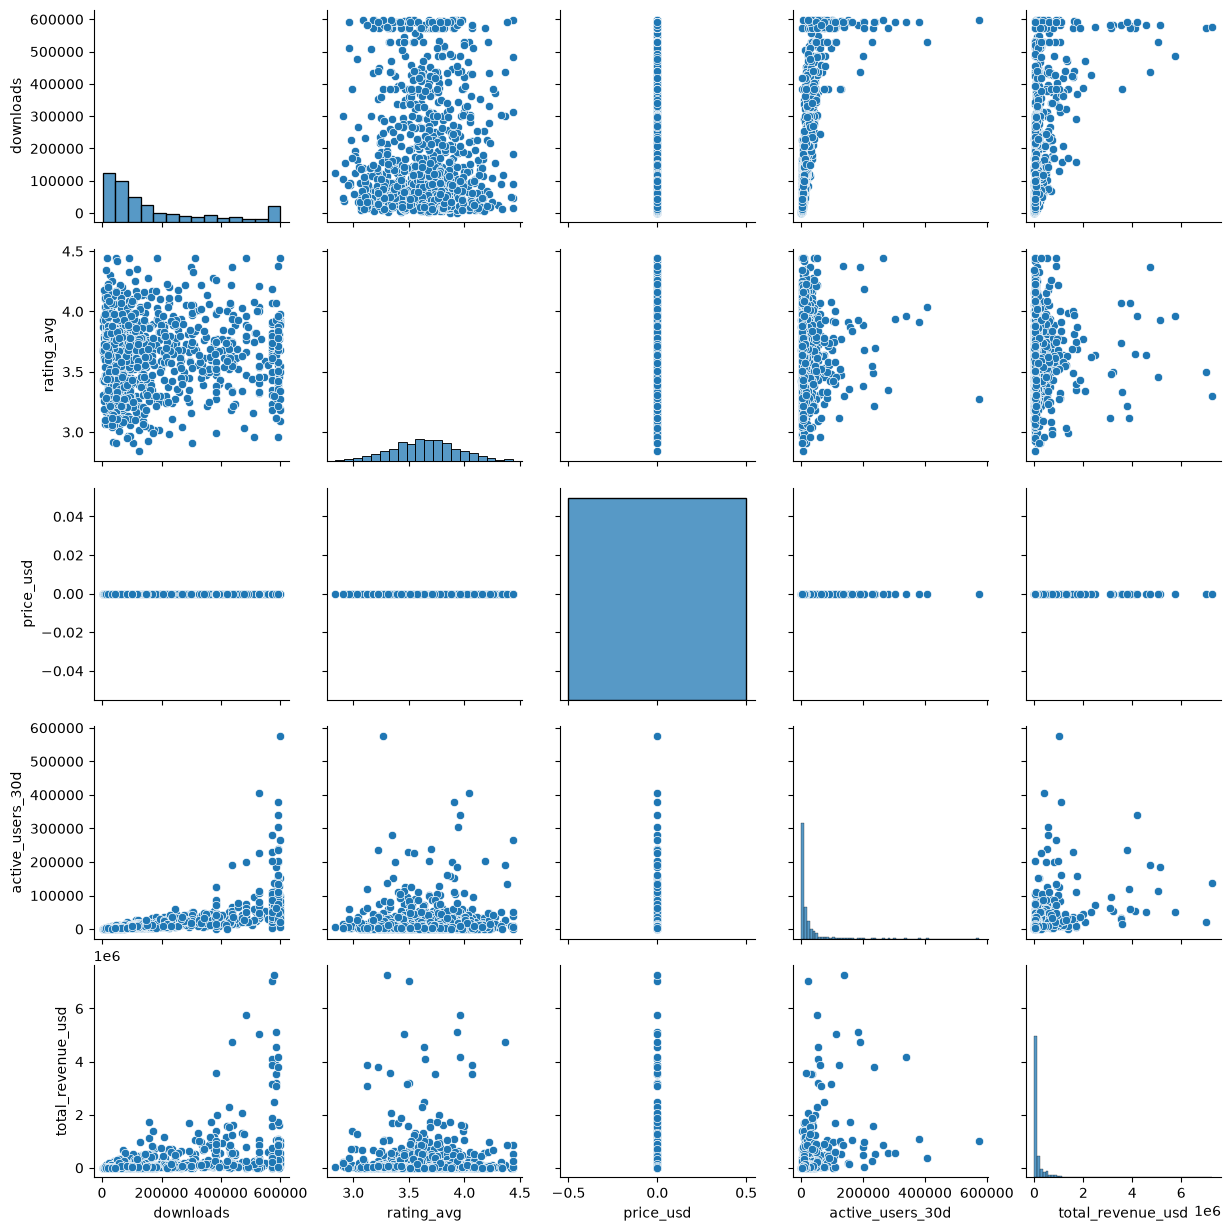

In [30]:
sns.pairplot(df[['downloads', 'rating_avg', 'price_usd',
                 'active_users_30d', 'total_revenue_usd']].sample(1000, random_state=42))

plt.show()

## Insights : 

* Multiple numerical variables between relationships can be observed.
* Downloads vary across different ratings and prices.
* Active users generally vary with downloads.
* Total revenue varies across different game performance measures.

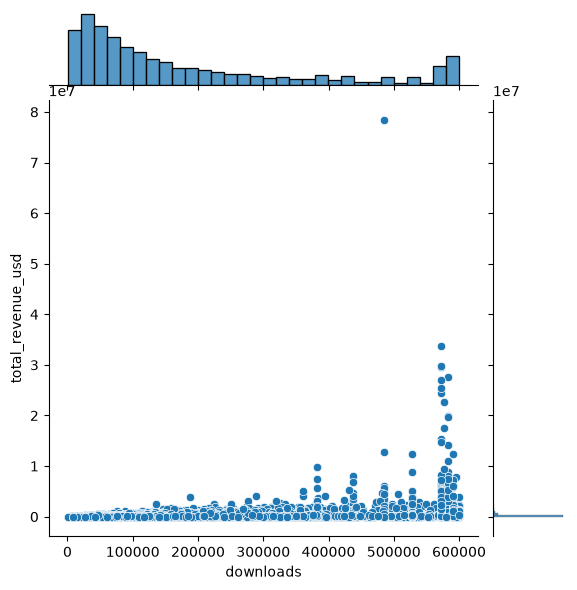

In [31]:
sns.jointplot(
    x='downloads',
    y='total_revenue_usd',
    data=df,
    kind='scatter'
)

plt.show()

## Insights

* Downloads and total revenue show variation together.
* Games with higher downloads can have different revenue levels.
* The points show the spread of games across both variables.
* The distributions of downloads and revenue are also visible.